<a href="https://colab.research.google.com/github/Janani-hari/BMSCE-DATA-VISUALIZATION/blob/main/lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using Colab cache for faster access to the 'sandp500' dataset.


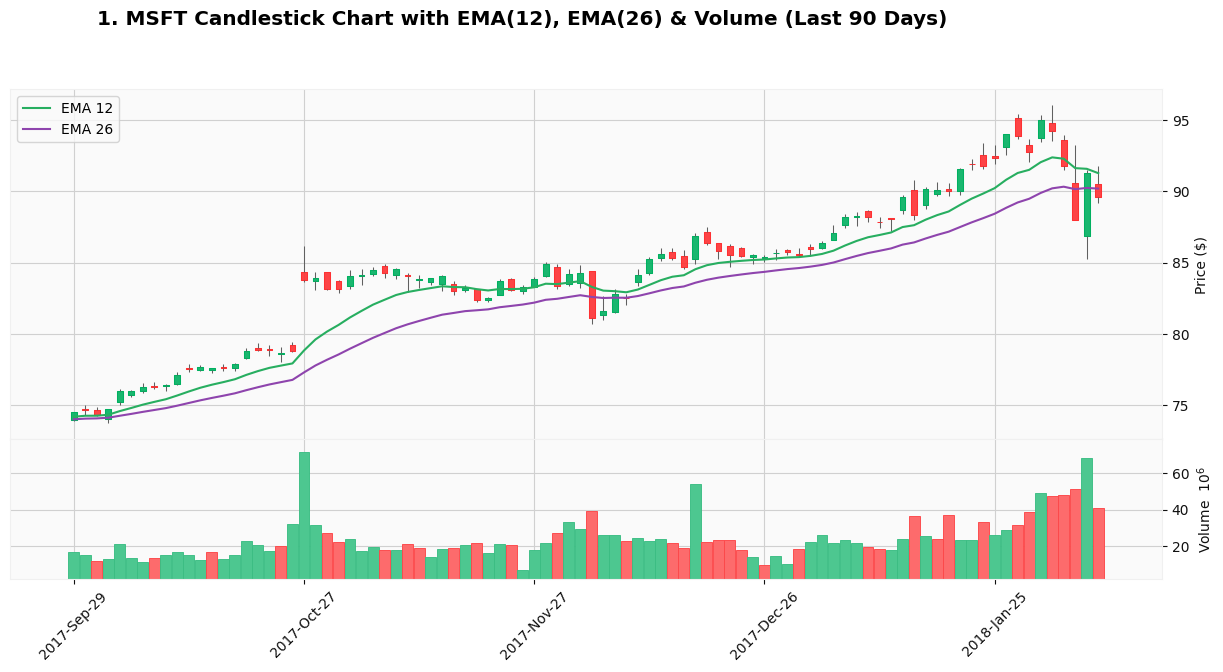

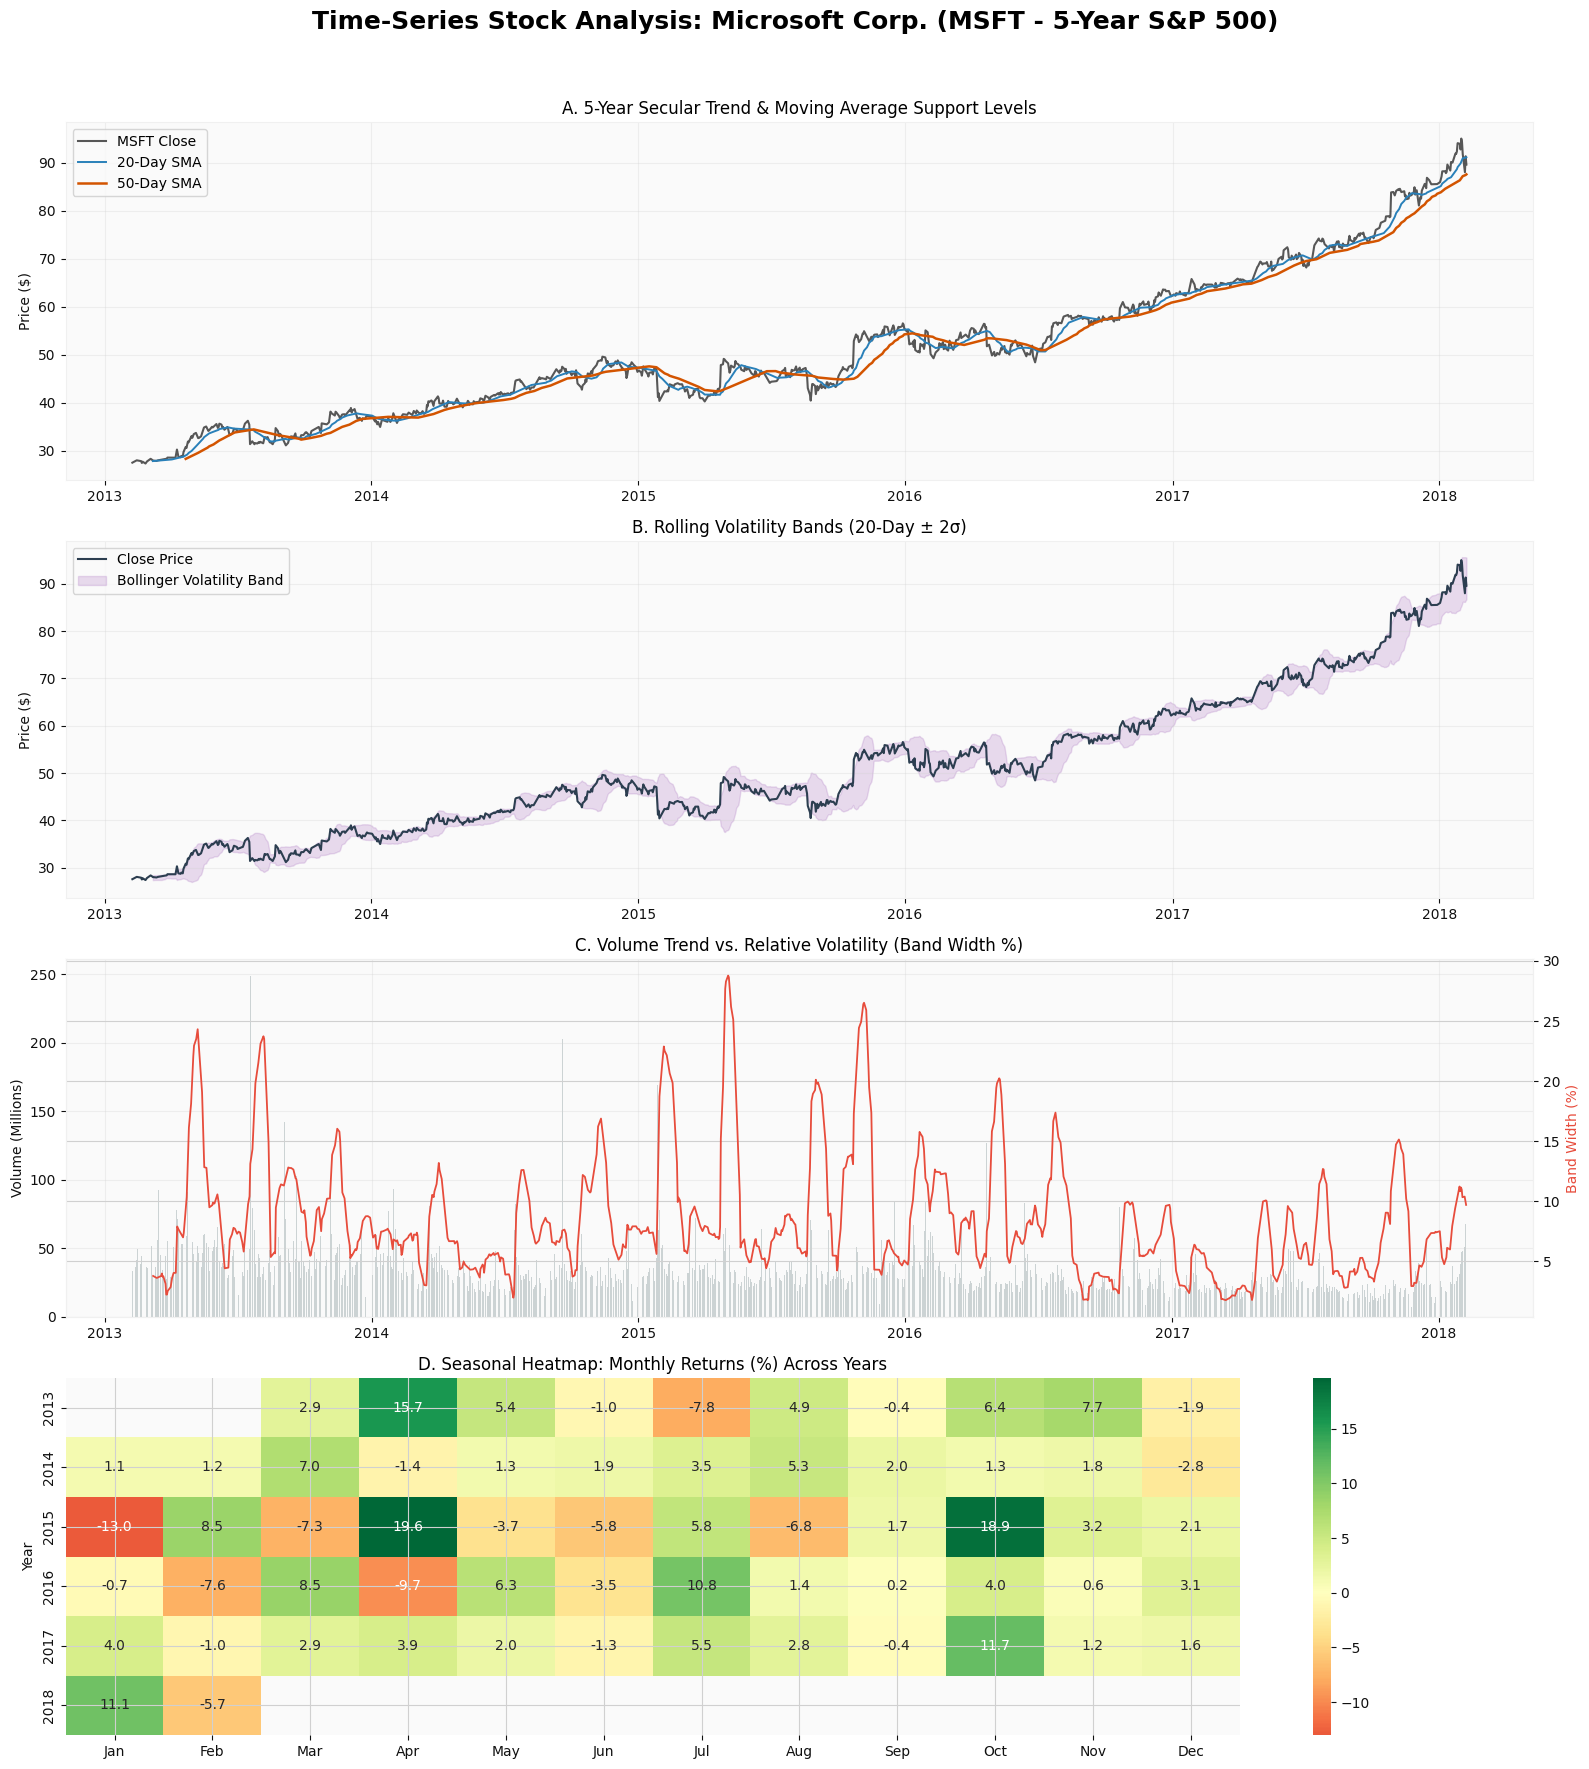

--- MSFT Summary Metrics & Variable Correlations ---
              Close  Volume  Band_Width  Daily_Return
Close         1.000  -0.365      -0.203         0.028
Volume       -0.365   1.000       0.241        -0.040
Band_Width   -0.203   0.241       1.000         0.023
Daily_Return  0.028  -0.040       0.023         1.000


In [1]:
!pip install -q mplfinance kagglehub

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mplfinance as mpf
import os

# 1. Download Dataset directly via KaggleHub
path = kagglehub.dataset_download("camnugent/sandp500")
csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
full_df = pd.read_csv(os.path.join(path, csv_file))

# Filter for Microsoft (MSFT) & prepare time-series index
df = full_df[full_df['Name'] == 'MSFT'].copy()
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').set_index('date')
df.rename(columns={'open': 'Open', 'high': 'High', 'low': 'Low', 'close': 'Close', 'volume': 'Volume'}, inplace=True)

# Technical Indicators
df['SMA_20'] = df['Close'].rolling(20).mean()
df['SMA_50'] = df['Close'].rolling(50).mean()
df['EMA_12'] = df['Close'].ewm(span=12, adjust=False).mean()
df['EMA_26'] = df['Close'].ewm(span=26, adjust=False).mean()

# Rolling Volatility Bands
df['Std_20'] = df['Close'].rolling(20).std()
df['Upper_BB'] = df['SMA_20'] + 2 * df['Std_20']
df['Lower_BB'] = df['SMA_20'] - 2 * df['Std_20']
df['Band_Width'] = (df['Upper_BB'] - df['Lower_BB']) / df['SMA_20'] * 100 # Normalized Volatility %
df['Daily_Return'] = df['Close'].pct_change()

# --- VISUALIZATION 1: Candlestick Chart with Fast/Slow EMA & Volume (Last 90 Days) ---
recent_msft = df.tail(90)
apds = [
    mpf.make_addplot(recent_msft['EMA_12'], color='#27ae60', width=1.5, label='EMA 12'),
    mpf.make_addplot(recent_msft['EMA_26'], color='#8e44ad', width=1.5, label='EMA 26')
]
mpf.plot(
    recent_msft,
    type='candle',
    style='yahoo',
    title='1. MSFT Candlestick Chart with EMA(12), EMA(26) & Volume (Last 90 Days)',
    ylabel='Price ($)',
    volume=True,
    addplot=apds,
    figsize=(16, 7)
)

# --- VISUALIZATION 2: Multi-Panel Time-Series Evaluation ---
fig, axes = plt.subplots(4, 1, figsize=(16, 18))
fig.suptitle('Time-Series Stock Analysis: Microsoft Corp. (MSFT - 5-Year S&P 500)', fontsize=18, fontweight='bold', y=0.98)

# Panel A: 5-Year Secular Trend with SMA(20) and SMA(50)
axes[0].plot(df.index, df['Close'], label='MSFT Close', color='black', alpha=0.65)
axes[0].plot(df.index, df['SMA_20'], label='20-Day SMA', color='#2980b9', linewidth=1.4)
axes[0].plot(df.index, df['SMA_50'], label='50-Day SMA', color='#d35400', linewidth=1.8)
axes[0].set_title('A. 5-Year Secular Trend & Moving Average Support Levels')
axes[0].set_ylabel('Price ($)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Panel B: Rolling Volatility Bands
axes[1].plot(df.index, df['Close'], color='#2c3e50', label='Close Price')
axes[1].fill_between(df.index, df['Upper_BB'], df['Lower_BB'], color='#9b59b6', alpha=0.2, label='Bollinger Volatility Band')
axes[1].set_title('B. Rolling Volatility Bands (20-Day ± 2σ)')
axes[1].set_ylabel('Price ($)')
axes[1].legend()
axes[1].grid(alpha=0.3)

# Panel C: Volume Trend & Normalized Band Width (Volatility Squeeze Indicator)
ax2_twin = axes[2].twinx()
axes[2].bar(df.index, df['Volume'] / 1e6, color='#95a5a6', alpha=0.45, label='Volume (M)')
ax2_twin.plot(df.index, df['Band_Width'], color='#e74c3c', linewidth=1.3, label='Bollinger Band Width (%)')
axes[2].set_title('C. Volume Trend vs. Relative Volatility (Band Width %)')
axes[2].set_ylabel('Volume (Millions)')
ax2_twin.set_ylabel('Band Width (%)', color='#e74c3c')
axes[2].grid(alpha=0.3)

# Panel D: Seasonal Heatmap (Year vs Month Average Monthly Return %)
monthly_ret = df['Close'].resample('ME').last().pct_change() * 100
season_df = pd.DataFrame({'Year': monthly_ret.index.year, 'Month': monthly_ret.index.month, 'Return': monthly_ret.values})
pivot_season = season_df.pivot(index='Year', columns='Month', values='Return')
pivot_season.columns = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
sns.heatmap(pivot_season, annot=True, fmt='.1f', cmap='RdYlGn', center=0, cbar=True, ax=axes[3])
axes[3].set_title('D. Seasonal Heatmap: Monthly Returns (%) Across Years')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Print Key Relationships
print("--- MSFT Summary Metrics & Variable Correlations ---")
print(df[['Close', 'Volume', 'Band_Width', 'Daily_Return']].corr().round(3))